# Exploration : nuages et NDVI sur les zones pilotes (2025)

Ce notebook résume deux calculs faits côté Google Earth Engine sur les trois zones pilotes
(Sfax, Béja, Kairouan) pour les 12 mois de 2025 :

1. la comparaison des masques de nuages (SCL et Cloud Score+, seuils 0,5 / 0,6 / 0,7),
   voir `docs/adr/0002-masque-nuages.md` ;
2. les composites mensuels médians (masque Cloud Score+ à 0,6, au moins 2 observations
   claires par pixel).

Les tableaux lus ici sont dans `data/interim/` (ignoré par Git). Pour les regénérer :

```
uv run python -m tdm.gee.explore --year 2025
uv run python -m tdm.gee.composites --year 2025
```

**Limites** : une seule année, des moyennes sur tout le gouvernorat (champs, steppe, sol nu,
villes), calculées à une résolution grossière (20 m pour les masques, 100 m pour les
composites). Les profils par classe d'occupation viendront avec les étiquettes.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
INTERIM = ROOT / "data" / "interim"
FIGURES = ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

ZONES = ["sfax", "beja", "kairouan"]
METHODS = ["scl", "cs50", "cs60", "cs70"]

clouds = pd.read_csv(INTERIM / "s2_cloud_exploration_2025.csv")
composites = pd.read_csv(INTERIM / "composites_check_2025.csv")
print(f"{len(clouds)} lignes (nuages), {len(composites)} lignes (composites)")

36 lignes (nuages), 36 lignes (composites)


## 1. Observations claires par pixel selon le masque de nuages

Nombre moyen d'observations claires par pixel dans le mois : plus il est grand, plus le
composite est robuste. Les méthodes se séparent surtout en saison humide.

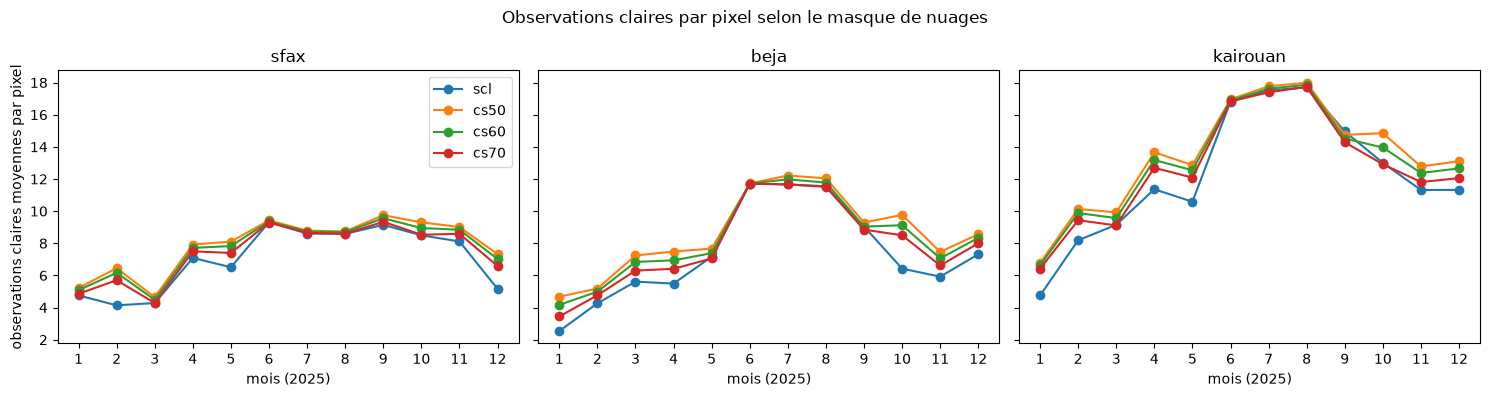

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, zone in zip(axes, ZONES, strict=True):
    subset = clouds[clouds["zone"] == zone].sort_values("month")
    for method in METHODS:
        ax.plot(subset["month"], subset[f"obs_{method}"], marker="o", label=method)
    ax.set_title(zone)
    ax.set_xlabel("mois (2025)")
    ax.set_xticks(range(1, 13))
axes[0].set_ylabel("observations claires moyennes par pixel")
axes[0].legend()
fig.suptitle("Observations claires par pixel selon le masque de nuages")
fig.tight_layout()
fig.savefig(FIGURES / "masques_nuages_2025.png", dpi=150)
plt.show()

## 2. Tuiles Sentinel-2 disponibles par mois

On compte des tuiles (morceaux d'image), pas des dates de passage : des tuiles voisines se
recouvrent, ce qui explique le nombre plus élevé à Kairouan.

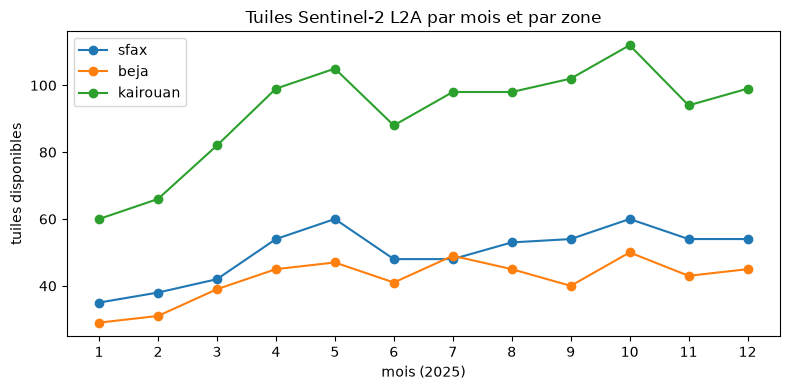

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
for zone in ZONES:
    subset = clouds[clouds["zone"] == zone].sort_values("month")
    ax.plot(subset["month"], subset["n_images"], marker="o", label=zone)
ax.set_xticks(range(1, 13))
ax.set_xlabel("mois (2025)")
ax.set_ylabel("tuiles disponibles")
ax.set_title("Tuiles Sentinel-2 L2A par mois et par zone")
ax.legend()
fig.tight_layout()
plt.show()

## 3. Part de pixels valides dans les composites

Un pixel est valide s'il a au moins 2 observations claires dans le mois ; sinon il reste vide.

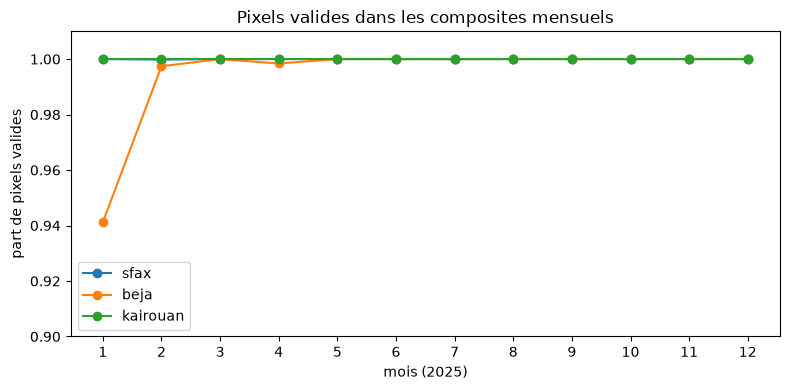

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for zone in ZONES:
    subset = composites[composites["zone"] == zone].sort_values("month")
    ax.plot(subset["month"], subset["valid"], marker="o", label=zone)
ax.set_xticks(range(1, 13))
ax.set_ylim(0.9, 1.01)
ax.set_xlabel("mois (2025)")
ax.set_ylabel("part de pixels valides")
ax.set_title("Pixels valides dans les composites mensuels")
ax.legend()
fig.tight_layout()
plt.show()

## 4. Profil saisonnier du NDVI par zone

NDVI moyen des pixels valides du composite mensuel, à 100 m.

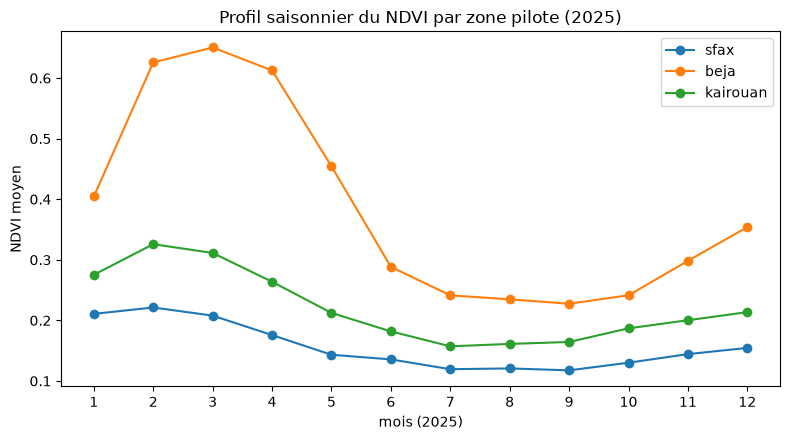

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for zone in ZONES:
    subset = composites[composites["zone"] == zone].sort_values("month")
    ax.plot(subset["month"], subset["ndvi"], marker="o", label=zone)
ax.set_xticks(range(1, 13))
ax.set_xlabel("mois (2025)")
ax.set_ylabel("NDVI moyen")
ax.set_title("Profil saisonnier du NDVI par zone pilote (2025)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "ndvi_profils_2025.png", dpi=150)
plt.show()

In [6]:
summary = composites.groupby("zone").agg(
    ndvi_min=("ndvi", "min"), ndvi_max=("ndvi", "max"), valid_min=("valid", "min")
)
peak_rows = composites.loc[composites.groupby("zone")["ndvi"].idxmax()].set_index("zone")
summary["mois_du_pic"] = peak_rows["month"]
print(summary.round(3).to_string())

          ndvi_min  ndvi_max  valid_min  mois_du_pic
zone                                                
beja         0.227     0.651      0.941            3
kairouan     0.157     0.326      1.000            2
sfax         0.118     0.221      1.000            2


## Constats (à valider, une seule année)

- Béja (céréales) montre un cycle net : NDVI maximal en mars (0,65), puis forte baisse
  d'avril à juin (0,61 à 0,29). C'est compatible avec un cycle de céréales d'hiver.
- Sfax (oliviers) et Kairouan (zone mixte) ont un NDVI bas et peu variable, avec un léger
  maximum en hiver.
- Les composites sont valides à plus de 94 % des pixels toute l'année ; la valeur la plus
  faible est Béja en janvier (0,941).
- Ces moyennes mélangent plusieurs types de surface. La validation viendra avec des années
  sèches documentées et les profils par classe d'occupation du sol.